In [1]:
%pip install langgraph

  Using cached xxhash-3.5.0-cp312-cp312-win_amd64.whl.metadata (13 kB)
Using cached xxhash-3.5.0-cp312-cp312-win_amd64.whl (30 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-4o-mini", temperature=0)
model.invoke("Hello, how are you?")

AIMessage(content="Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 13, 'total_tokens': 42, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_62a23a81ef', 'id': 'chatcmpl-C0ITOJfpLLDDRL4Jgqdt0ZsE8fLLz', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--1bec6b33-5e55-4a48-afc3-b4ee05cce077-0', usage_metadata={'input_tokens': 13, 'output_tokens': 29, 'total_tokens': 42, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [3]:
# 상태 정의하기
from typing import Annotated # annotated 는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict 는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict 를 상속 받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 'list'타입을 가집니다.
        'add_messages' 함수는 이 상태 키가 어떻게 업데이트 되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프 생성
graph_builder = StateGraph(State)

In [4]:
# 노드 생성하기
def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
        state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.

    반환값:
        dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리.
            형식은 {"messages": [응답 메시지]} 입니다.
    """
    return {"messages": [model.invoke(state["messages"])]}

graph_builder.add_node("generate", generate)

In [5]:
# graph 선언하기
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

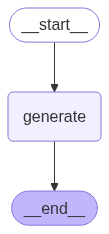

In [6]:
# 그래프 도식화하기
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [8]:
# 리스트에 문장 추가하기
response = graph.invoke({"messages": ["안녕? 나는 홍길동이야."]})

print(type(response))
print(response)

<class 'dict'>
{'messages': [HumanMessage(content='안녕? 나는 홍길동이야.', additional_kwargs={}, response_metadata={}, id='264d3735-030d-46b8-a3b8-f09ec9a989aa'), AIMessage(content='안녕하세요, 홍길동님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 17, 'total_tokens': 32, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_34a54ae93c', 'id': 'chatcmpl-C0Iivzmp05jR0jNzPVJ0YyIpip8gO', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--d8248032-086c-45ca-8b15-ee26ca358fd1-0', usage_metadata={'input_tokens': 17, 'output_tokens': 15, 'total_tokens': 32, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})]}


In [9]:
response["messages"].append("제 이름을 아시나요?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕? 나는 홍길동이야.', additional_kwargs={}, response_metadata={}, id='264d3735-030d-46b8-a3b8-f09ec9a989aa'),
  AIMessage(content='안녕하세요, 홍길동님! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 17, 'total_tokens': 32, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_34a54ae93c', 'id': 'chatcmpl-C0Iivzmp05jR0jNzPVJ0YyIpip8gO', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--d8248032-086c-45ca-8b15-ee26ca358fd1-0', usage_metadata={'input_tokens': 17, 'output_tokens': 15, 'total_tokens': 32, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  HumanMessage(content='제 이름을 아시나

In [10]:
# 스트림 방식으로 출력하기
inputs = {"messages": [("human", "한국과 일본의 관계에 대해 자세히 알려줘.")]}

for chunk, _ in graph.stream(inputs, stream_mode="messages"):
    print(chunk.content, end="")

한국과 일본의 관계는 역사적으로 복잡하고 다층적인 측면을 가지고 있습니다. 두 나라의 관계는 여러 가지 요소에 의해 영향을 받으며, 다음과 같은 주요 주제를 통해 설명할 수 있습니다.

### 1. 역사적 배경
- **일제 강점기 (1910-1945)**: 한국은 1910년부터 1945년까지 일본의 식민지로 지배받았습니다. 이 시기에 많은 한국인들이 고통을 겪었고, 문화와 언어가 억압당했습니다. 이 시기의 경험은 현재까지도 양국 관계에 큰 영향을 미치고 있습니다.
- **전후 처리**: 제2차 세계대전 이후, 일본은 한국과의 관계를 정상화하기 위해 여러 조치를 취했습니다. 1965년 한일 기본 조약이 체결되었고, 이로 인해 양국 간의 외교 관계가 수립되었습니다. 그러나 이 조약에 대한 해석과 역사적 책임 문제는 여전히 논란이 되고 있습니다.

### 2. 경제적 관계
- **무역**: 한국과 일본은 서로 중요한 무역 파트너입니다. 일본은 한국의 주요 수출국 중 하나이며, 한국도 일본에 많은 제품을 수출합니다. 두 나라 간의 경제적 상호 의존도는 높습니다.
- **기술 협력**: 일본은 한국의 기술 발전에 큰 영향을 미쳤으며, 양국 간의 기술 협력도 활발히 이루어지고 있습니다.

### 3. 정치적 관계
- **영토 분쟁**: 독도(일본에서는 다케시마로 불림)를 둘러싼 영토 분쟁은 양국 간의 긴장을 유발하는 주요 요인 중 하나입니다. 이 문제는 역사적, 감정적 요소가 얽혀 있어 해결이 쉽지 않습니다.
- **군사적 협력**: 북한의 위협에 대응하기 위해 한국과 일본은 미국과의 삼각 군사 협력을 강화하고 있습니다. 그러나 역사적 문제로 인해 군사적 협력이 항상 원활하지는 않습니다.

### 4. 사회문화적 관계
- **문화 교류**: 최근 몇 년간 K-팝, 한국 드라마, 일본 애니메이션 등 문화 교류가 활발해졌습니다. 이러한 문화적 상호작용은 양국 국민 간의 이해를 높이는 데 기여하고 있습니다.
- **여행과 관광**: 한국과 일본 간의 관광도 활발하며, 많은 사